In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df=pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [ ]:
df.shape

In [ ]:
df.head()

In [ ]:
df.tail()

In [ ]:
df.describe()

In [ ]:
df.info()

In [ ]:
df['Churn'].value_counts()

In [ ]:
df['TotalCharges']

In [ ]:
df['SeniorCitizen'].value_counts()

Data cleaning

This is where The TotalCharge is showing object we need to make this as float/int/numeric

In [ ]:
df[df['TotalCharges']==" "]

In [ ]:
df['TotalCharges']=pd.to_numeric(
    df['TotalCharges'],
    errors='coerce')# empty str N/A kore dei

In [ ]:
df.info()

In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

DROP CUSTOMER ID

In [ ]:
df=df.drop('customerID',axis=1)

OUTPUT _ ONE HOT ENCODE YES OR NO

In [ ]:
df['Churn']=df['Churn'].map({'Yes':1,'No':0})

**EDA**

Numeric ones

In [ ]:
numerical_features= df.select_dtypes(include='number').columns

In [ ]:
numerical_features

In [ ]:
df.describe()

In [ ]:
numerical_features[1:4]

In [ ]:
for i in numerical_features[1:4]:
  sns.histplot(data=df,x=i,kde=True)
  plt.show()

Groupby -> Mean

In [ ]:
df.groupby("Churn")[numerical_features[1:4]].agg(["mean", "median"])

In [ ]:
bins = [0, 12, 24, 36, 48, 60, 72]

labels = [
    '0-12 Months',
    '13-24 Months',
    '25-36 Months',
    '37-48 Months',
    '49-60 Months',
    '61-72 Months'
]

df['tenure_group'] = pd.cut(
    df['tenure'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [ ]:
df['tenure_group'].value_counts().sort_index()

In [ ]:
churn_rate = df.groupby('tenure_group')['Churn'].mean()*100
churn_rate

categorical

In [ ]:
categorical_features=df.select_dtypes(include='object').columns

In [ ]:
categorical_features

In [ ]:
df.info()

In [ ]:
df.drop(columns='tenure_group',inplace=True)

In [ ]:
df.info()

In [ ]:
df.groupby('gender')['Churn'].mean()

In [ ]:
for i in categorical_features:
  print(f'Churn rate by {i}:')
  print(df.groupby(i)['Churn'].mean()*100)
  print()

In [ ]:
# Collapse the redundant 'No ... service' categories into 'No'
df = df.replace({'No internet service': 'No', 'No phone service': 'No'})

Interaction analysis: do combinations create sharper segments?

In [ ]:
pd.crosstab(df['gender'], df['SeniorCitizen'])

In [ ]:

pd.crosstab(df['InternetService'],
    df['Contract'],
    values=df['Churn'],
    aggfunc='mean'
) * 100

Observation: Fiber + month-to-month = ~55% — the worst segment in the data. The two risks stack.

In [ ]:
pd.crosstab(
    df['InternetService'],
    df['TechSupport'],
    values=df['Churn'],
    aggfunc='mean'
) *100

Observation: fiber customers without tech support ~49%, but with tech support ~23% — tech support roughly halves fiber churn.

Are these signals independent, or overlapping?
Important check: if "risky" features describe the same customers, they aren't separate pieces of evidence.

In [ ]:
#month to month
#customer disproportinaley use electronic check

(df[df["Contract"] == "Month-to-month"]["PaymentMethod"]
 .value_counts(normalize=True) * 100).round(1)

In [ ]:
df.duplicated().sum()

Extra checks because one model is linear (Logistic Regression)

In [ ]:
# (1) Multicollinearity: are numeric features redundant with each other?
sns.heatmap(df[["tenure", "MonthlyCharges", "TotalCharges"]].corr(),
            annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Numeric feature correlations")
plt.show()

In [ ]:
df[['tenure','MonthlyCharges','TotalCharges','SeniorCitizen','Churn']].corr()

What are "log-odds"?
Logistic Regression (coming up soon) doesn't model churn probability as a straight line — it models the log-odds of churn as a straight line. Odds are simply

, i.e. the chance of churning divided by the chance of staying, and log-odds is just the natural log of that.

Why check this? The model assumes each numeric feature nudges the log-odds up or down at a steady rate. The plot below bins a feature and shows the real log-odds for each bin: if the dots fall on a roughly straight line, that assumption holds and we can use the feature as-is. A strong curve would tell us to transform or bin it first.

In [ ]:
 #(2) Linearity in the log-odds: logistic regression assumes each numeric feature is
# linear vs the log-odds of churn
def logodds_by_bin(col):
    b = pd.qcut(df[col], 10, duplicates="drop")
    g = df.groupby(b, observed=True)["Churn"].mean().clip(0.01, 0.99)
    return np.log(g / (1 - g))


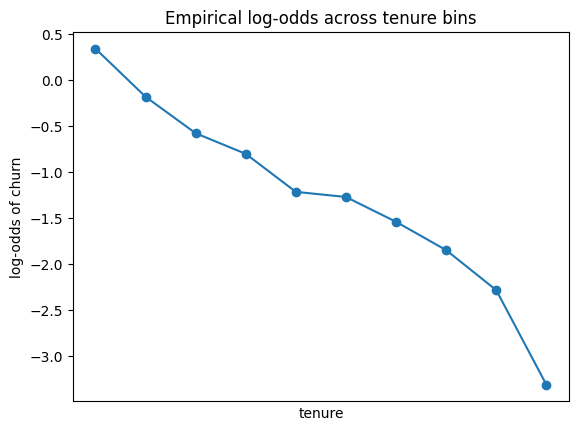

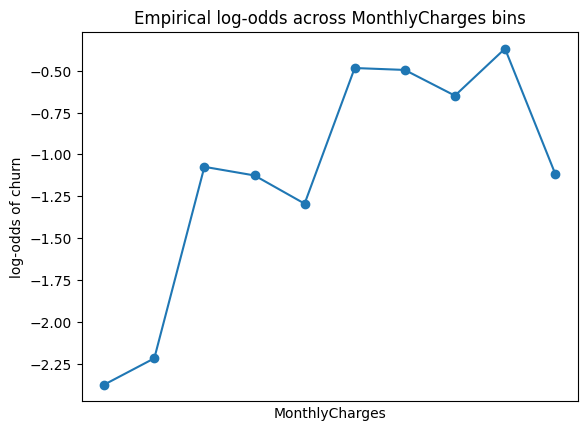

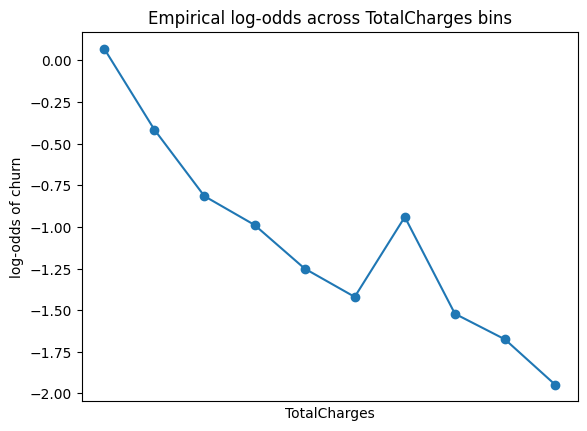

In [105]:
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    logodds_by_bin(col).plot(marker="o")
    plt.title(f"Empirical log-odds across {col} bins")
    plt.ylabel("log-odds of churn")
    plt.xticks([])
    plt.show()

Feature Engineering

In [106]:
# #service
# service_cols=['PhoneService','MultipleLines',
#               'OnlineSecurity',
#               'OnlineBackup','DeviceProtection',
#               'TechSupport','StreamingTV','StreamingMovies']

In [107]:
# df['num_services']=(df[service_cols]=='Yes').sum(axis=1)

In [108]:
# #avg spend per month of tenure
# df['avg_charge']=(df['TotalCharges'])/df['tenure'].replace(0,1)

In [109]:
# #brand new customer
# df['is_new']=(df['tenure']<12).astype(int)

In [110]:
# #dead combo : fiber optic AND month to month
# df['fiber_m2m'] = ((df['InternetService'] == 'Fiber optic') &
#                    (df['Contract'] == 'Month-to-month')).astype(int)

In [111]:
# # 1. number of services the customer has
# service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity',
#                 'OnlineBackup', 'DeviceProtection', 'TechSupport',
#                 'StreamingTV', 'StreamingMovies']
# df['num_services'] = (df[service_cols] == 'Yes').sum(axis=1)

# # 2. average spend per month of tenure (replace 0 with 1 to avoid divide by zero)
# df['avg_charge'] = df['TotalCharges'] / df['tenure'].replace(0, 1)

# # 3. brand new customer flag (first-year danger zone)
# df['is_new'] = (df['tenure'] < 12).astype(int)

# # 4. dead combo: fiber optic AND month-to-month
# df['fiber_m2m'] = ((df['InternetService'] == 'Fiber optic') &
#                    (df['Contract'] == 'Month-to-month')).astype(int)

In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


ENCODING

In [113]:
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
               'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
               'StreamingTV', 'StreamingMovies', 'PaperlessBilling']

binary_maps = {'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0}

for col in binary_cols:
    df[col] = df[col].map(binary_maps)

In [114]:
 #Multi-category columns (no natural order) -> one-hot; drop_first avoids the dummy-variable trap
df = pd.get_dummies(df, columns=["InternetService", "Contract", "PaymentMethod"],
                    drop_first=True, dtype=int)

In [115]:
df.columns.tolist()

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'PaperlessBilling',
 'MonthlyCharges',
 'TotalCharges',
 'Churn',
 'InternetService_Fiber optic',
 'InternetService_No',
 'Contract_One year',
 'Contract_Two year',
 'PaymentMethod_Credit card (automatic)',
 'PaymentMethod_Electronic check',
 'PaymentMethod_Mailed check']

In [116]:
df.shape

(7043, 24)

In [117]:
df.isnull().sum().sum()

np.int64(0)

In [118]:
df.isnull().sum()[df.isnull().sum() > 0]

,0


In [119]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,29.85,29.85,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,56.95,1889.50,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,53.85,108.15,1,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,42.30,1840.75,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,70.70,151.65,1,1,0,0,0,0,1,0


In [120]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 24 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7043 non-null   int64  
 1   SeniorCitizen                          7043 non-null   int64  
 2   Partner                                7043 non-null   int64  
 3   Dependents                             7043 non-null   int64  
 4   tenure                                 7043 non-null   int64  
 5   PhoneService                           7043 non-null   int64  
 6   MultipleLines                          7043 non-null   int64  
 7   OnlineSecurity                         7043 non-null   int64  
 8   OnlineBackup                           7043 non-null   int64  
 9   DeviceProtection                       7043 non-null   int64  
 10  TechSupport                            7043 non-null   int64  
 11  Stre

TRAIN TEST SPLIT

In [121]:
x=df.drop('Churn',axis=1)
y=df['Churn']

In [122]:
y.value_counts()

,count
Churn,
0,5174
1,1869


In [123]:
from sklearn.model_selection import train_test_split

In [131]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

Feature Scaling

In [132]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [133]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)  # FIT on train
x_test_scaled  = scaler.transform(x_test)       # transform test only
print('Scaled. Example')

Scaled. Example


In [135]:
x_train_scaled=pd.DataFrame(x_train_scaled,columns=x_train.columns)
x_test_scaled=pd.DataFrame(x_test_scaled,columns=x_test.columns)

In [136]:
x_train,x_test=x_train_scaled.copy(),x_test_scaled.copy()

Class Imbalance + Baseline Model -> Logistic regression


In [139]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)


In [140]:
logreg.fit(x_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [153]:
# Predictions and churn probabilities
pred  = logreg.predict(x_test)
proba = logreg.predict_proba(x_test)[:,1]


In [154]:
pred

array([1, 0, 0, ..., 0, 0, 1])

In [155]:
proba

array([0.84880858, 0.15981718, 0.01292415, ..., 0.12893918, 0.03713732,
       0.71082332])

In [156]:
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             accuracy_score, roc_auc_score)


In [157]:
print("Recall   :", round(recall_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, proba), 3))

Recall   : 0.823
Precision: 0.516
ROC-AUC  : 0.862


Model 2 : RANDOM FOREST

In [163]:
from sklearn.ensemble import RandomForestClassifier

In [164]:
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=42, n_jobs=-1)

In [168]:
rf.fit(x_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=-1,
                       random_state=42)

In [170]:
pred  = rf.predict(x_test)
proba = rf.predict_proba(x_test)[:, 1]

In [171]:
print("Recall   :", round(recall_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, proba), 3))

Recall   : 0.44
Precision: 0.656
ROC-AUC  : 0.846


MODEL 3 : XGBOOASt

In [172]:
from xgboost import XGBClassifier

In [173]:
# scale_pos_weight is XGBoost's version of class_weight (ratio of stay:churn)
ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4,
                    subsample=0.9, scale_pos_weight=ratio,
                    eval_metric="logloss", random_state=42, n_jobs=-1)

In [176]:
xgb.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=400, n_jobs=-1,
              num_parallel_tree=None, ...)

In [178]:
pred  = xgb.predict(x_test)
proba = xgb.predict_proba(x_test)[:, 1]

In [179]:
print("Recall   :", round(recall_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, proba), 3))

Recall   : 0.791
Precision: 0.541
ROC-AUC  : 0.857


Compare the models

In [181]:

# Collect the fitted models, then score them all the same way
models = {"Logistic Regression": logreg, "Random Forest": rf, "XGBoost": xgb}

rows = []
for name, model in models.items():
    pred  = model.predict(x_test)
    proba = model.predict_proba(x_test)[:, 1]
    rows.append({
        "model":     name,
        "recall":    round(recall_score(y_test, pred), 3),
        "precision": round(precision_score(y_test, pred), 3),
        "roc_auc":   round(roc_auc_score(y_test, proba), 3),
    })
pd.DataFrame(rows).sort_values("recall", ascending=False).reset_index(drop=True)

,model,recall,precision,roc_auc
0,Logistic Regression,0.823,0.516,0.862
1,XGBoost,0.791,0.541,0.857
2,Random Forest,0.440,0.656,0.846


Hyperparameter tuning

In [182]:
from sklearn.model_selection import GridSearchCV, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)


In [184]:
lr_grid = GridSearchCV(
    LogisticRegression(max_iter=2000, class_weight="balanced"),
    {"C": [0.05, 0.1, 0.5, 1, 2]}, scoring="roc_auc", cv=cv, n_jobs=-1)


In [185]:
lr_grid.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LogisticRegression(class_weight='balanced',
                                          max_iter=2000),
             n_jobs=-1, param_grid={'C': [0.05, 0.1, 0.5, 1, 2]},
             scoring='roc_auc')

In [186]:
print("best C:", lr_grid.best_params_, "| CV ROC-AUC:", round(lr_grid.best_score_, 3))

best C: {'C': 2} | CV ROC-AUC: 0.841


# Tune XGBoost — depth and learning rate

In [187]:
xgb_grid = GridSearchCV(
    XGBClassifier(eval_metric="logloss", scale_pos_weight=ratio, random_state=42, n_jobs=-1),
    {"max_depth": [3, 4], "learning_rate": [0.03, 0.05], "n_estimators": [300]},
    scoring="roc_auc", cv=cv, n_jobs=-1)

In [189]:
xgb_grid.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=True,
                                     eval_metric='logloss', feature_types=None,
                                     feature_weights=None, gamma=None,
                                     grow_policy=None...
                                     learning_rate=None, max_bin=None,
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=-1, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.03, 0.05], 'max_depth': [3, 4],
                         'n_estimators': [300]},
             scoring='roc_auc')

In [190]:
print("best params:", xgb_grid.best_params_, "| CV ROC-AUC:", round(xgb_grid.best_score_, 3))

best params: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300} | CV ROC-AUC: 0.842


#Threshold tuning


In [192]:
# Use the tuned Logistic Regression and try different cutoffs
best_lr = lr_grid.best_estimator_
proba = best_lr.predict_proba(x_test)[:, 1]

rows = []
for t in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    pred = (proba >= t).astype(int)
    rows.append({
        "threshold": t,
        "recall":    round(recall_score(y_test, pred), 3),
        "precision": round(precision_score(y_test, pred), 3),
        "caught":    int(((pred == 1) & (y_test == 1)).sum()),
        "missed":    int(((pred == 0) & (y_test == 1)).sum()),
    })

pd.DataFrame(rows)

,threshold,recall,precision,caught,missed
0,0.25,0.960,0.411,358,15
1,0.30,0.944,0.428,352,21
2,0.35,0.936,0.448,349,24
3,0.40,0.895,0.466,334,39
4,0.45,0.863,0.489,322,51
5,0.50,0.823,0.513,307,66
6,0.55,0.791,0.558,295,78
7,0.60,0.740,0.575,276,97


Save the model

In [193]:

FINAL_THRESHOLD=0.40

In [196]:
import joblib

joblib.dump(best_lr, "churn_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(FINAL_THRESHOLD, "threshold.pkl")
print("Model, scaler and threshold saved!")

Model, scaler and threshold saved!


In [197]:
model = joblib.load("churn_model.pkl")
scaler = joblib.load("scaler.pkl")
threshold = joblib.load("threshold.pkl")


In [199]:
# The first 3 customers in our test set (by their original row index)
sample=x_test[0:5]

In [200]:
sample_scaled = scaler.transform(sample)

In [201]:
probabilities = model.predict_proba(sample_scaled)

In [202]:
probabilities

array([[9.94256310e-02, 9.00574369e-01],
       [8.37828815e-01, 1.62171185e-01],
       [9.99007064e-01, 9.92935953e-04],
       [4.63410292e-03, 9.95365897e-01],
       [9.51595713e-01, 4.84042874e-02]])

In [203]:

probabilities[:,1]

array([9.00574369e-01, 1.62171185e-01, 9.92935953e-04, 9.95365897e-01,
       4.84042874e-02])

In [204]:
predictions = (probabilities[:,1] >= 0.8).astype(int)

In [205]:


predictions

array([1, 0, 0, 1, 0])

In [206]:

y_test[:5]

,Churn
185,1
2715,0
3825,0
1807,1
132,0


Why Logistic Regression is our pick — interpretability
Logistic Regression gives a coefficient per feature. Exponentiating it gives an odds ratio — a plain-English statement of how each feature changes churn odds. This is the business-friendly payoff a black-box model can't match.

In [208]:
# Odds ratio for each feature (>1 = raises churn odds, <1 = lowers it)
odds = pd.Series(np.exp(best_lr.coef_[0]), index=x_train.columns)
odds.sort_values(ascending=False).round(2)


,0
InternetService_Fiber optic,2.22
TotalCharges,1.88
StreamingMovies,1.37
StreamingTV,1.30
MultipleLines,1.21
PaymentMethod_Electronic check,1.18
PaperlessBilling,1.17
SeniorCitizen,1.06
DeviceProtection,1.05
PhoneService,1.04


**GOAL**

learn the patterns associated with customers who leave